# Jordan SMR Site Selection — ML Pipeline

**Working title:** *A Multi-Criteria Machine Learning Framework for Small Modular Reactor Site Selection in Water-Scarce Economies: A Jordan Case Study*

This notebook implements the **two-stage ML pipeline** after data preparation:
- **Stage 1:** Binary classification (viable vs not) using rule-based labels from IAEA SSG-35 criteria and a Logistic Regression classifier.
- **Stage 2:** Continuous suitability scoring (0–1) with XGBoost, water features weighted 2× for the water–energy nexus.
- **Explainability:** SHAP values; final heatmap and top candidate sites.

---
## Section 1 — Setup & Imports

We set the project root from the current working directory so the notebook runs on any machine. All paths are relative to `PROJECT_ROOT`. We load the feature table produced by the data-prep pipeline (`output/final/jordan_smr_features.csv`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score
)
import xgboost as xgb
import shap
import warnings
warnings.filterwarnings('ignore')

# Project root: run notebook from project root (databases/)
PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "output" / "final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load feature table from data-prep pipeline
csv_path = OUTPUT_DIR / "jordan_smr_features.csv"
df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

/Users/rajinasrallah/Desktop/databases/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Shape: (151156, 20)

First 5 rows:


,cell_id,row,col,x_utm,y_utm,lon,lat,elevation_m,slope_deg,pga,dist_river_km,dist_lake_km,dist_dead_sea_km,water_occurrence,population_density,dist_power_km,dist_road_km,mean_temp_c,precip_mm_annual,viable
0,951,1,420,1067500.0,3728500.0,39.108336,33.545333,NaN,NaN,0.073247,0.649885,35.097206,386.220014,0.0,0.0,108.669840,89.464592,NaN,NaN,1
1,952,1,421,1068500.0,3728500.0,39.119046,33.544802,NaN,NaN,0.073236,1.124474,35.412168,387.054867,0.0,0.0,108.700545,89.515329,NaN,NaN,1
2,953,1,422,1069500.0,3728500.0,39.129756,33.544270,NaN,NaN,0.073225,1.723793,35.752217,387.890500,0.0,0.0,108.740438,89.577201,NaN,NaN,1
3,1477,2,416,1063500.0,3727500.0,39.064864,33.538478,NaN,NaN,0.073653,0.989835,33.111443,382.333559,0.0,0.0,107.639078,88.373317,NaN,NaN,1
4,1478,2,417,1064500.0,3727500.0,39.075574,33.537951,NaN,NaN,0.073653,0.982332,33.328154,383.166440,0.0,0.0,107.632920,88.379432,NaN,NaN,1


---
## Section 2 — Exploratory Data Analysis

We visualize feature distributions (histograms), correlation structure, and the spatial pattern of viable vs eliminated cells. Summary statistics support the methodology section of the paper.

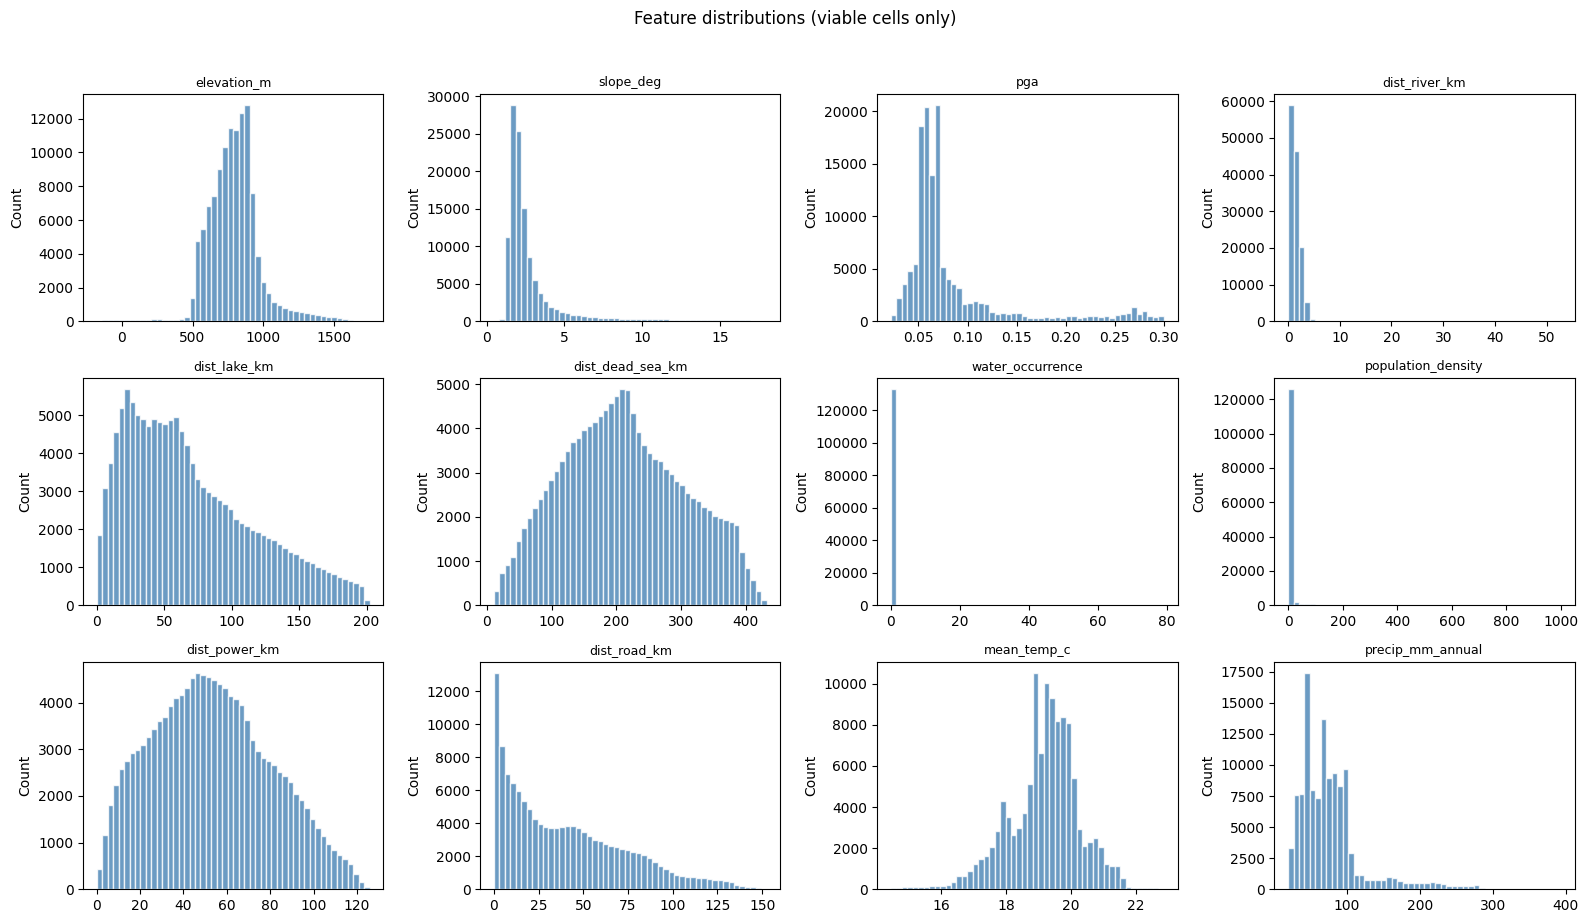

In [2]:
FEATURE_COLS = [
    'elevation_m', 'slope_deg', 'pga', 'dist_river_km', 'dist_lake_km', 'dist_dead_sea_km',
    'water_occurrence', 'population_density', 'dist_power_km', 'dist_road_km',
    'mean_temp_c', 'precip_mm_annual'
]
available = [c for c in FEATURE_COLS if c in df.columns]

# Histograms for all 12 features (viable cells only for cleaner distributions)
df_viable = df[df['viable'] == 1].copy()
nfeat = len(available)
ncols = 4
nrows = (nfeat + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = axes.flatten()
for i, col in enumerate(available):
    ax = axes[i]
    ser = df_viable[col].dropna()
    if len(ser) > 0:
        ax.hist(ser, bins=50, color='steelblue', alpha=0.8, edgecolor='white')
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('Count')
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Feature distributions (viable cells only)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_feature_histograms.png', dpi=120, bbox_inches='tight')
plt.show()

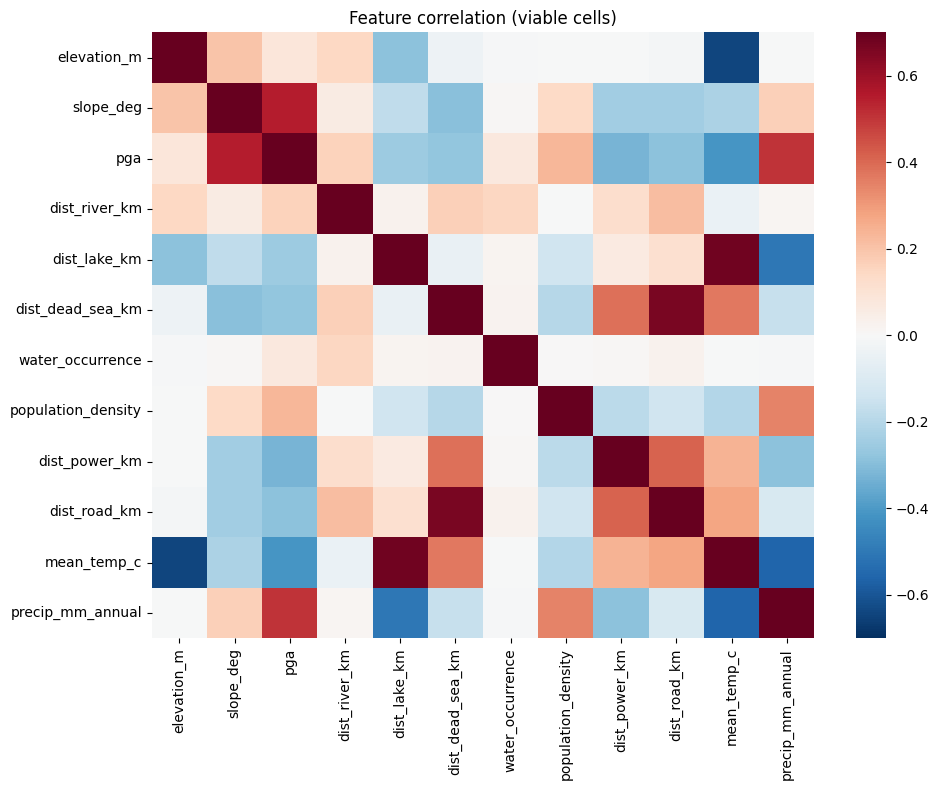

In [3]:
# Correlation heatmap
corr = df_viable[available].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=False, cmap='RdBu_r', center=0, vmin=-0.7, vmax=0.7, ax=ax)
ax.set_title('Feature correlation (viable cells)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

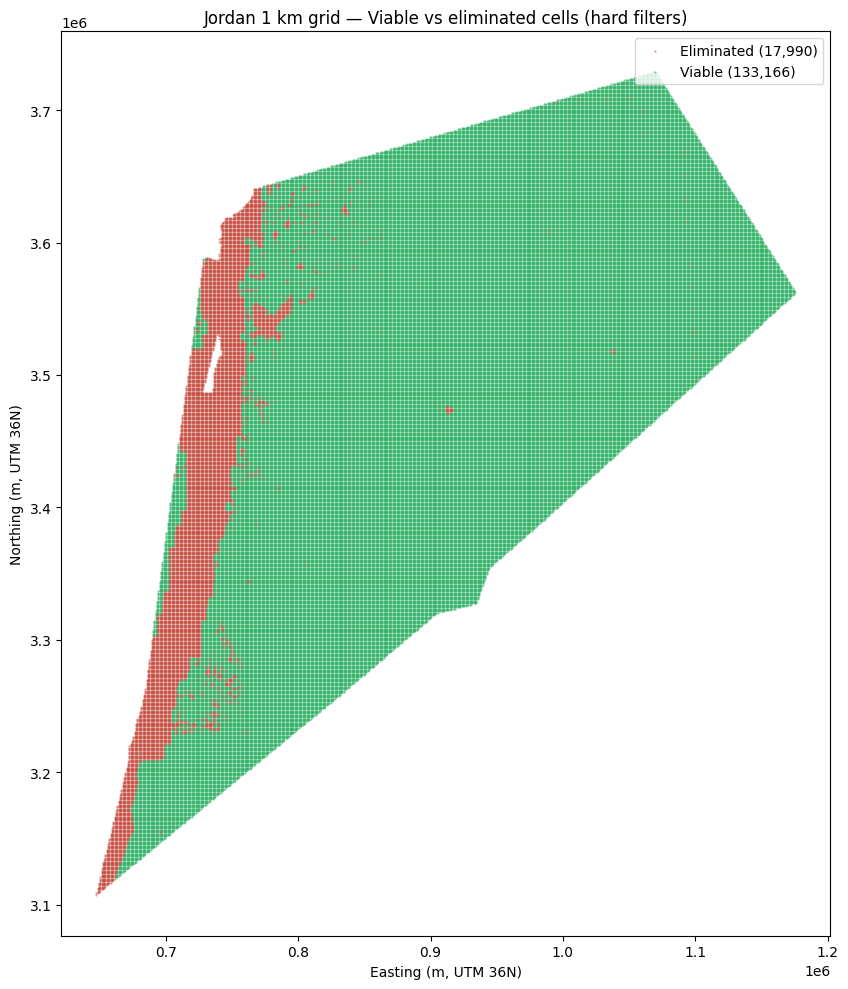

In [4]:
# Map: viable vs eliminated cells (UTM)
fig, ax = plt.subplots(figsize=(10, 10))
elim = df[df['viable'] == 0]
via = df[df['viable'] == 1]
if len(elim) > 0:
    ax.scatter(elim['x_utm'], elim['y_utm'], c='#c0392b', s=0.3, alpha=0.5, label=f'Eliminated ({len(elim):,})', rasterized=True)
if len(via) > 0:
    ax.scatter(via['x_utm'], via['y_utm'], c='#27ae60', s=0.3, alpha=0.6, label=f'Viable ({len(via):,})', rasterized=True)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Jordan 1 km grid — Viable vs eliminated cells (hard filters)')
ax.legend(loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_viable_eliminated_map.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Summary statistics table
summary = df_viable[available].describe().T[['mean', 'std', 'min', 'max']].round(4)
summary['count'] = df_viable[available].count()
summary = summary[['count', 'mean', 'std', 'min', 'max']]
print('Summary statistics (viable cells):')
summary

Summary statistics (viable cells):


,count,mean,std,min,max
elevation_m,117328,793.9562,184.7678,-177.4728,1753.4370
slope_deg,117328,2.8919,2.3751,0.4684,17.9956
pga,133164,0.0845,0.0567,0.0220,0.3000
dist_river_km,133166,1.5534,2.2006,0.0024,52.7647
dist_lake_km,133166,69.4477,47.0576,0.0097,202.3513
dist_dead_sea_km,133166,211.1881,93.2809,10.7546,432.5116
water_occurrence,133166,0.0272,1.2023,0.0000,79.0496
population_density,133166,10.8907,66.9275,0.0000,999.5786
dist_power_km,133166,53.2505,27.1502,0.1087,125.8691
dist_road_km,133166,40.3326,33.6247,0.0015,152.5646


---
## Section 3 — Label Generation (IAEA SSG-35 Based)

**IAEA Safety Standards SSG-35** (siting of nuclear installations) and related guidance recommend:
- Low seismic hazard (e.g. PGA below a threshold).
- Low population density and avoidance of dense urban areas.
- Stable terrain (moderate slope).
- Access to cooling water (proximity to rivers) while avoiding siting on permanent water bodies.
- Reasonable access to infrastructure (roads, grid).

We define **binary labels** for Stage 1:
- **Positive (highly suitable):** pga &lt; 0.15*g*, slope &lt; 5°, population &lt; 100/km², dist_river &lt; 10 km, water_occurrence &lt; 20, dist_road &lt; 50 km (all criteria met).
- **Negative:** Passed hard filters but does not meet all positive criteria.

Only **viable** cells (that passed the hard filters) are used for labeling and training.

In [6]:
# Restrict to viable cells for labeling and ML
df_ml = df[df['viable'] == 1].copy()

# Rule-based positive: all of the following must hold
pga_ok      = df_ml['pga'].fillna(1) < 0.15
slope_ok    = df_ml['slope_deg'].fillna(90) < 5
pop_ok      = df_ml['population_density'].fillna(1e6) < 100
river_ok    = df_ml['dist_river_km'].fillna(1e6) < 10
water_ok    = df_ml['water_occurrence'].fillna(0) < 20
road_ok     = df_ml['dist_road_km'].fillna(1e6) < 50

df_ml['label_positive'] = (pga_ok & slope_ok & pop_ok & river_ok & water_ok & road_ok).astype(int)

n_pos = df_ml['label_positive'].sum()
n_neg = len(df_ml) - n_pos
print('Class distribution (viable cells only):')
print(f'  Positive (highly suitable): {n_pos:,}')
print(f'  Negative:                    {n_neg:,}')
print(f'  Fraction positive:           {n_pos/len(df_ml):.2%}')

Class distribution (viable cells only):
  Positive (highly suitable): 65,996
  Negative:                    67,170
  Fraction positive:           49.56%


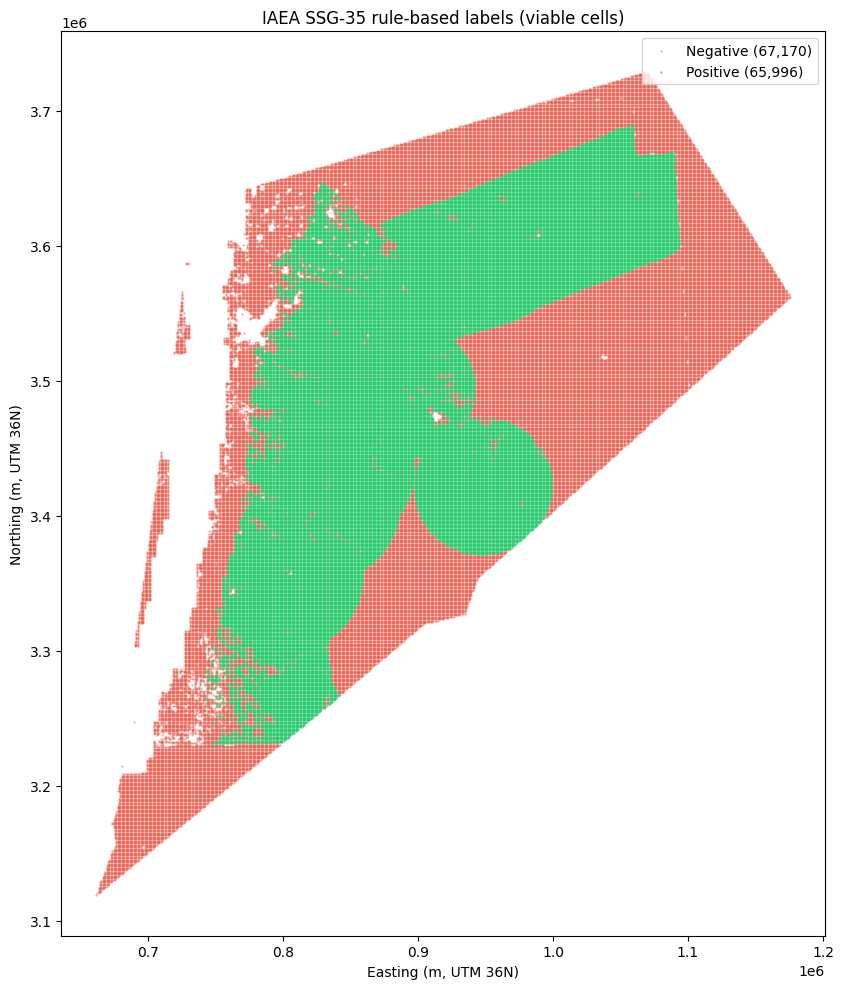

In [7]:
# Map: positive vs negative cells
fig, ax = plt.subplots(figsize=(10, 10))
neg = df_ml[df_ml['label_positive'] == 0]
pos = df_ml[df_ml['label_positive'] == 1]
if len(neg) > 0:
    ax.scatter(neg['x_utm'], neg['y_utm'], c='#e74c3c', s=0.3, alpha=0.5, label=f'Negative ({len(neg):,})', rasterized=True)
if len(pos) > 0:
    ax.scatter(pos['x_utm'], pos['y_utm'], c='#2ecc71', s=0.5, alpha=0.7, label=f'Positive ({len(pos):,})', rasterized=True)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('IAEA SSG-35 rule-based labels (viable cells)')
ax.legend(loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'labels_positive_negative_map.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 4 — Stage 1: Logistic Regression Classifier

We train a **Logistic Regression** classifier on the rule-based binary labels using the 12 features. An 80/20 train/test split is used; metrics (accuracy, precision, recall, F1, confusion matrix, ROC curve) support the paper's methodology. Predictions are stored as `stage1_label`.

In [8]:
# Prepare X, y — drop rows with missing labels or too many missing features
use_cols = [c for c in FEATURE_COLS if c in df_ml.columns]
X_full = df_ml[use_cols].copy()
y_full = df_ml['label_positive']
# Impute missing with median for LR
for c in use_cols:
    X_full[c] = X_full[c].fillna(X_full[c].median())

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

print('Stage 1 — Logistic Regression')
print('  Accuracy:  ', round(accuracy_score(y_test, y_pred), 4))
print('  Precision: ', round(precision_score(y_test, y_pred, zero_division=0), 4))
print('  Recall:    ', round(recall_score(y_test, y_pred, zero_division=0), 4))
print('  F1:        ', round(f1_score(y_test, y_pred, zero_division=0), 4))
print('  AUC-ROC:   ', round(roc_auc_score(y_test, y_prob), 4))
print('\nConfusion matrix:')
print(confusion_matrix(y_test, y_pred))

Stage 1 — Logistic Regression
  Accuracy:   0.9414
  Precision:  0.9379
  Recall:     0.9444
  F1:         0.9411
  AUC-ROC:    0.988

Confusion matrix:
[[12608   826]
 [  734 12466]]


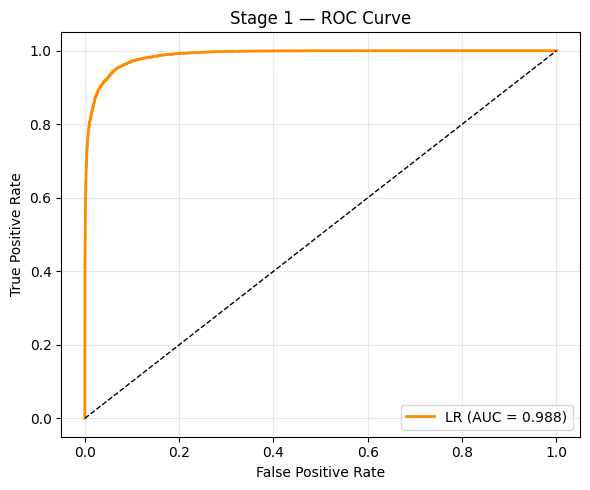

In [9]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'LR (AUC = {roc_auc_score(y_test, y_prob):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Stage 1 — ROC Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'stage1_roc_curve.png', dpi=120, bbox_inches='tight')
plt.show()

In [10]:
# Predict on full viable set and attach to df_ml
X_imputed = df_ml[use_cols].copy()
for c in use_cols:
    X_imputed[c] = X_imputed[c].fillna(X_imputed[c].median())
df_ml['stage1_label'] = lr.predict(X_imputed)
df_ml['stage1_prob'] = lr.predict_proba(X_imputed)[:, 1]
print('Stage1 predictions attached. Value counts:')
print(df_ml['stage1_label'].value_counts())

Stage1 predictions attached. Value counts:
stage1_label
0    66637
1    66529
Name: count, dtype: int64


---
## Section 5 — Stage 2: XGBoost Suitability Scoring

We build a **continuous suitability score (0–1)** using weighted feature contributions aligned with the water–energy nexus:
- **Water features (2× weight):** dist_river_km, dist_dead_sea_km, dist_lake_km, water_occurrence, precip_mm_annual.
- **Safety (1.5× weight):** pga, slope_deg.
- **Infrastructure (1× weight):** dist_road_km, dist_power_km, population_density.

We first construct a **target** from these weighted components (normalized to 0–1), then train an **XGBoost regressor** to predict it; the model's predictions serve as the final suitability score.

In [11]:
# Stage 2 — Weighted composite suitability score (no regression)
w = df_ml.copy()
for c in use_cols:
    w[c] = w[c].fillna(w[c].median())

def norm_minmax(s):
    m, M = s.min(), s.max()
    if M <= m:
        return pd.Series(0.5, index=s.index)
    return (s - m) / (M - m)

river_n  = 1 - norm_minmax(w['dist_river_km'])
dead_n   = 1 - norm_minmax(w['dist_dead_sea_km'])
lake_n   = 1 - norm_minmax(w['dist_lake_km'])
water_n  = 1 - norm_minmax(w['water_occurrence'])
precip_n = norm_minmax(w['precip_mm_annual'])
pga_n    = 1 - norm_minmax(w['pga'])
slope_n  = 1 - norm_minmax(w['slope_deg'])
road_n   = 1 - norm_minmax(w['dist_road_km'])
power_n  = 1 - norm_minmax(w['dist_power_km'])
pop_n    = 1 - norm_minmax(w['population_density'].clip(upper=w['population_density'].quantile(0.99)))

water_w  = 2.0
safety_w = 1.5
infra_w  = 1.0

score_raw = (
    water_w * (river_n + dead_n + lake_n + water_n + precip_n) / 5
    + safety_w * (pga_n + slope_n) / 2
    + infra_w * (road_n + power_n + pop_n) / 3
) / (water_w + safety_w + infra_w)

# Keep both suitability_target (for compatibility) and suitability_score (for plots)
df_ml['suitability_target'] = norm_minmax(score_raw)
df_ml['suitability_score'] = df_ml['suitability_target']
print("Composite suitability score summary:")
print(df_ml['suitability_score'].describe())


Composite suitability score summary:
count    133166.000000
mean          0.749093
std           0.101821
min           0.000000
25%           0.694936
50%           0.755070
75%           0.813202
max           1.000000
Name: suitability_score, dtype: float64


In [12]:
print('Composite suitability score summary (see previous cell).')
print(df_ml['suitability_score'].describe())


Composite suitability score summary (see previous cell).
count    133166.000000
mean          0.749093
std           0.101821
min           0.000000
25%           0.694936
50%           0.755070
75%           0.813202
max           1.000000
Name: suitability_score, dtype: float64


---
## Section 6 — SHAP Explainability

We compute **SHAP values** for the XGBoost model to interpret feature importance and direction of impact. The bar chart and beeswarm summary support the discussion of drivers of suitability in the paper.

Training XGBoost classifier on label_positive for SHAP analysis...


Top 5 most important features:
population_density    0.698553
dist_dead_sea_km      0.728412
pga                   1.873141
slope_deg             2.423819
dist_road_km          5.772686


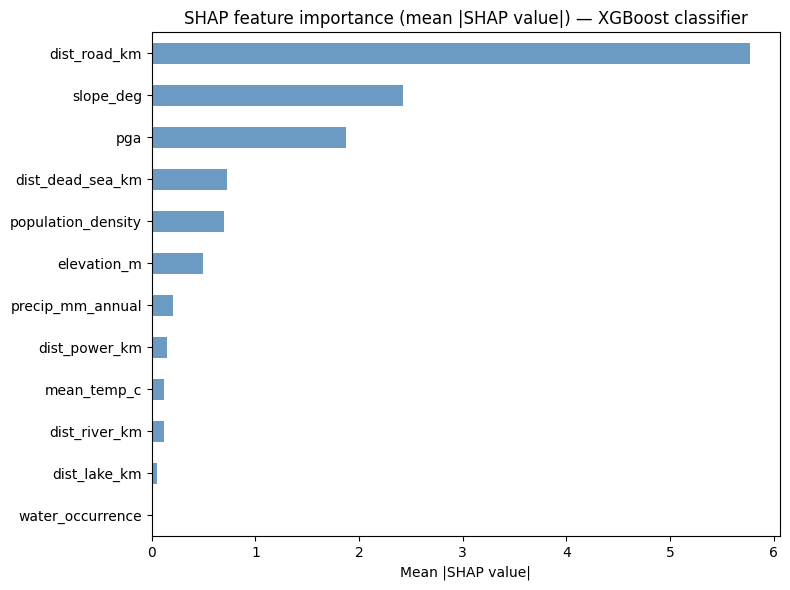

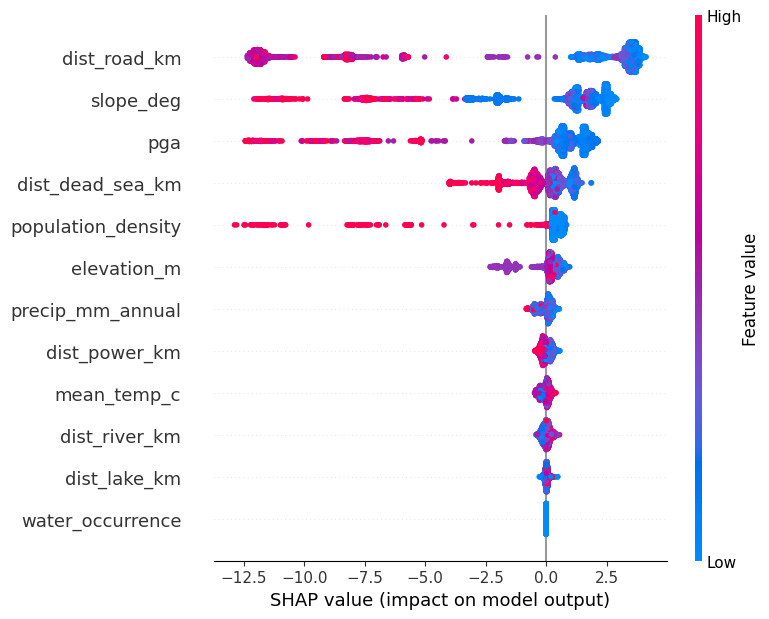

In [13]:
# SHAP explainability — XGBoost classifier on label_positive
print("Training XGBoost classifier on label_positive for SHAP analysis...")

X_shap_full = df_ml[use_cols].copy()
for c in use_cols:
    X_shap_full[c] = X_shap_full[c].fillna(X_shap_full[c].median())

y_shap_full = df_ml['label_positive']

# Downsample negatives if highly imbalanced
pos_idx = y_shap_full[y_shap_full == 1].index
neg_idx = y_shap_full[y_shap_full == 0].index
if len(pos_idx) > 0 and len(neg_idx) > 5 * len(pos_idx):
    neg_sample = neg_idx.to_series().sample(5 * len(pos_idx), random_state=42)
    idx_used = pos_idx.union(neg_sample)
    X_shap_full = X_shap_full.loc[idx_used]
    y_shap_full = y_shap_full.loc[idx_used]

xgb_clf = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=4,
)
xgb_clf.fit(X_shap_full, y_shap_full)

sample_size = min(5000, len(X_shap_full))
X_shap = X_shap_full.sample(sample_size, random_state=42)

explainer = shap.TreeExplainer(xgb_clf)
shap_vals = explainer.shap_values(X_shap)

importance = pd.Series(np.abs(shap_vals).mean(axis=0), index=use_cols).sort_values()
print("Top 5 most important features:")
print(importance.tail(5).to_string())

# Bar chart
fig, ax = plt.subplots(figsize=(8, 6))
importance.plot(kind='barh', ax=ax, color='steelblue', alpha=0.8)
ax.set_title('SHAP feature importance (mean |SHAP value|) — XGBoost classifier')
ax.set_xlabel('Mean |SHAP value|')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_importance.png', dpi=120, bbox_inches='tight')
plt.show()

# Beeswarm summary
fig, ax = plt.subplots(figsize=(8, 8))
shap.summary_plot(shap_vals, X_shap, show=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_beeswarm.png', dpi=120, bbox_inches='tight')
plt.show()

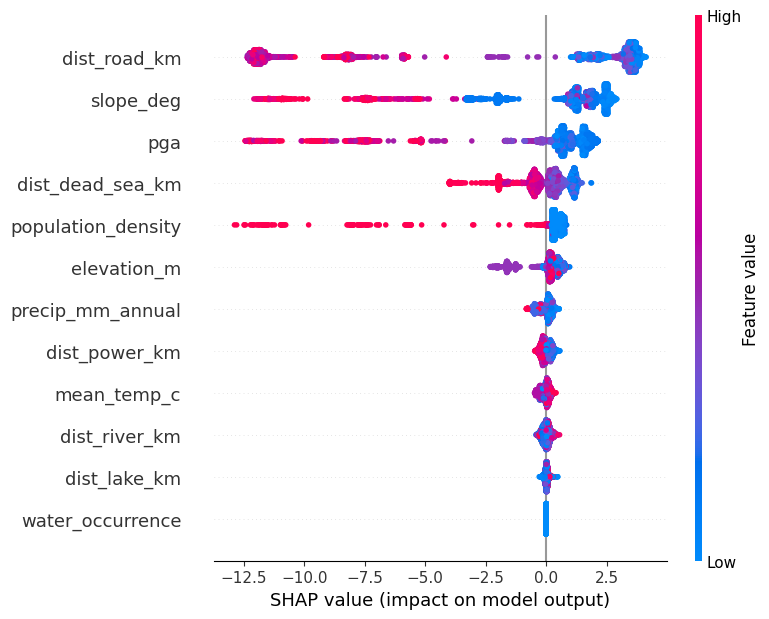

In [14]:
# SHAP summary (beeswarm)
fig, ax = plt.subplots(figsize=(8, 8))
shap.summary_plot(shap_vals, X_shap, show=False)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'shap_summary_beeswarm.png', dpi=120, bbox_inches='tight')
plt.show()

**Top 3 features (typical interpretation):**  
1. **dist_river_km** — Closer to rivers increases suitability (cooling water access).  
2. **pga** — Lower seismic hazard increases suitability (safety).  
3. **dist_road_km** or **population_density** — Better infrastructure access and lower population density favour siting.  

*(Interpret exact order from the SHAP bar chart and beeswarm in your run.)*

---
## Section 7 — Suitability Heatmap

We plot Jordan as a **heatmap** coloured by suitability score (red = high, blue = low). Only viable cells are included; eliminated cells can be shown in grey or omitted.

Suitability score distribution (viable cells):
  min : 0.0
  max : 1.0
  mean: 0.7490927658256038
  std : 0.10182092582346874
  p10 : 0.6412013541086048
  p90 : 0.8704186428782282
Using vmin = 0.5802017619553334 vmax = 0.9014471170206507 for colormap stretch


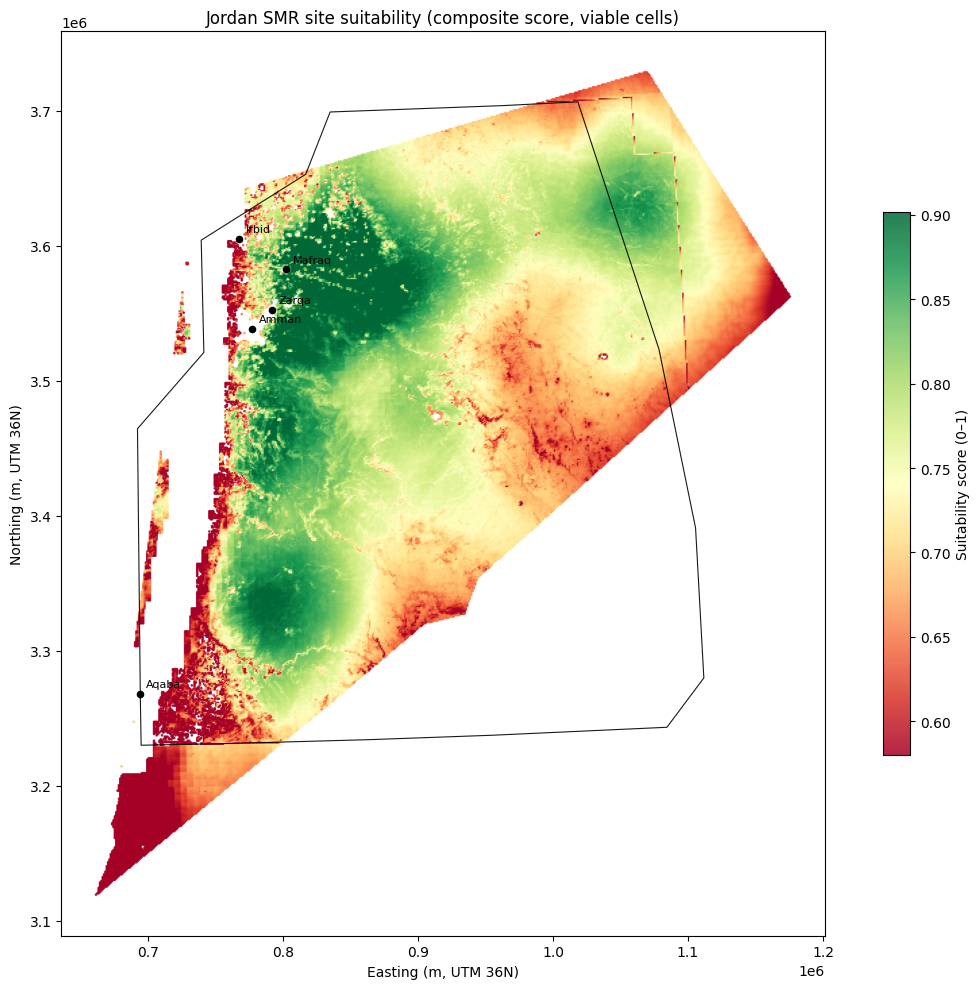

In [15]:
# Section 7 — Suitability heatmap with stretched colormap + context
from pyproj import Transformer

# Viable cells with suitability scores
viable_sc = df_ml[df_ml['suitability_score'].notna()].copy()

# Score distribution
s = viable_sc['suitability_score']
print("Suitability score distribution (viable cells):")
print("  min :", float(s.min()))
print("  max :", float(s.max()))
print("  mean:", float(s.mean()))
print("  std :", float(s.std()))
print("  p10 :", float(s.quantile(0.10)))
print("  p90 :", float(s.quantile(0.90)))

vmin = float(s.quantile(0.05))
vmax = float(s.quantile(0.95))
print("Using vmin =", vmin, "vmax =", vmax, "for colormap stretch")

fig, ax = plt.subplots(figsize=(12, 10))
sc = ax.scatter(
    viable_sc['x_utm'], viable_sc['y_utm'],
    c=viable_sc['suitability_score'],
    cmap='RdYlGn',  # red = low, green = high
    vmin=vmin, vmax=vmax,
    s=0.8, alpha=0.85, rasterized=True,
)

# Approximate Jordan border outline (same polygon as data-prep fallback)
transformer = Transformer.from_crs('EPSG:4326', 'EPSG:32636', always_xy=True)

jordan_coords_lonlat = [
    (35.005, 29.500), (35.005, 29.185), (35.720, 29.185),
    (36.750, 29.185), (37.680, 29.185), (39.005, 29.185),
    (39.305, 29.500), (39.305, 30.500), (39.100, 31.700),
    (38.570, 33.375), (37.980, 33.375), (37.000, 33.380),
    (36.600, 33.380), (36.390, 32.970), (35.550, 32.550),
    (35.550, 31.800), (35.020, 31.300), (35.005, 29.500),
]

jx, jy = zip(*[transformer.transform(lon, lat) for lon, lat in jordan_coords_lonlat])
ax.plot(jx, jy, color='black', linewidth=0.8, alpha=0.9)

# Major Jordanian cities
cities = {
    'Amman':  (35.93, 31.95),
    'Zarqa':  (36.09, 32.07),
    'Irbid':  (35.85, 32.55),
    'Aqaba':  (35.00, 29.53),
    'Mafraq': (36.21, 32.34),
}

for name, (lon, lat) in cities.items():
    x, y = transformer.transform(lon, lat)
    ax.scatter(x, y, c='black', s=20, zorder=5)
    ax.text(x + 5000, y + 5000, name, color='black', fontsize=8, zorder=6)

cb = plt.colorbar(sc, ax=ax, shrink=0.6)
cb.set_label('Suitability score (0–1)')
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Jordan SMR site suitability (composite score, viable cells)')
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'jordan_suitability_map.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Section 8 — Top Candidate Sites

We select the **top 20 cells** by suitability score and report their coordinates, score, and key features. These are plotted on the Jordan map and saved to CSV.

In [16]:
top20 = df_ml.nlargest(20, 'suitability_score')
cols_out = ['cell_id', 'lon', 'lat', 'x_utm', 'y_utm', 'suitability_score', 'stage1_label', 'stage1_prob'] + use_cols
cols_out = [c for c in cols_out if c in top20.columns]
top20_export = top20[cols_out].copy()
top20_export.to_csv(OUTPUT_DIR / 'jordan_top_sites.csv', index=False)

print('Top 20 candidate sites:')
display(top20_export[['cell_id', 'lon', 'lat', 'suitability_score'] + use_cols[:6]])

Top 20 candidate sites:


,cell_id,lon,lat,suitability_score,elevation_m,slope_deg,pga,dist_river_km,dist_lake_km,dist_dead_sea_km
47777,88662,36.165011,32.159442,1.000000,564.175903,1.805253,0.093978,1.004678,0.212672,70.941519
46880,87605,36.197408,32.176658,0.996183,555.707520,2.062670,0.093969,0.878831,3.216606,74.516742
46434,87078,36.229498,32.184857,0.988082,581.429932,2.117467,0.093938,0.549935,6.176607,77.447552
46430,87074,36.187131,32.185933,0.986180,555.230713,2.464657,0.093978,0.544250,3.159302,74.430112
46432,87076,36.208315,32.185397,0.982181,570.088318,2.609269,0.093938,0.749442,4.609665,75.927482
38930,78074,36.298583,32.336327,0.981770,662.913696,1.609011,0.102630,0.835795,22.852296,93.422235
46431,87075,36.197723,32.185665,0.980088,563.643066,2.596478,0.093967,0.574125,3.854852,75.175874
46433,87077,36.218906,32.185127,0.979670,579.528870,2.605374,0.093938,1.028994,5.395747,76.684763
46881,87606,36.207999,32.176389,0.979570,569.680908,2.738818,0.093938,1.274424,3.984397,75.274932
46879,87604,36.186817,32.176925,0.979251,549.222107,2.962999,0.093978,0.133319,2.440783,73.764316


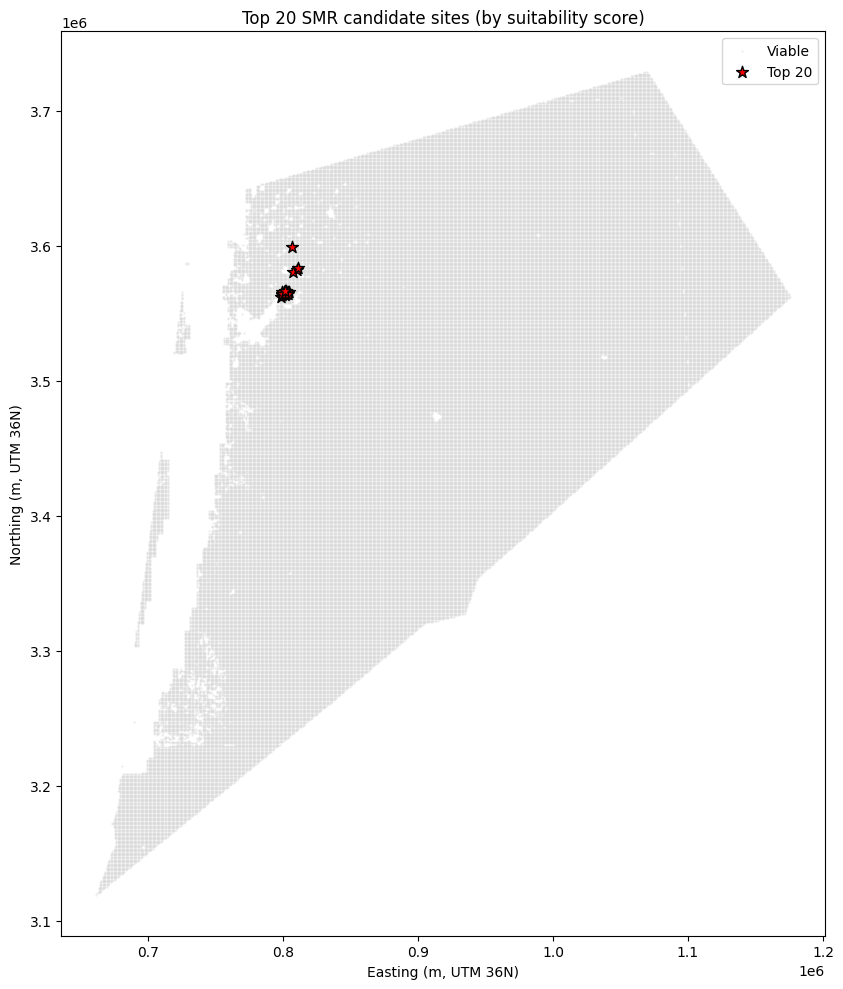

In [17]:
# Plot top 20 on Jordan map
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(df_ml['x_utm'], df_ml['y_utm'], c='lightgray', s=0.2, alpha=0.5, label='Viable', rasterized=True)
ax.scatter(top20['x_utm'], top20['y_utm'], c='red', s=80, marker='*', edgecolors='black', label='Top 20', zorder=5)
ax.set_xlabel('Easting (m, UTM 36N)')
ax.set_ylabel('Northing (m, UTM 36N)')
ax.set_title('Top 20 SMR candidate sites (by suitability score)')
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'jordan_top20_map.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Section 9 — Save Final Outputs

We merge the ML outputs (stage1_label, stage1_prob, suitability_score, suitability_target, label_positive) back into the full feature table where applicable, and save **jordan_smr_features_final.csv**. Non-viable cells keep NaN for ML columns.

In [18]:
# Left join ML columns from df_ml onto df (all cells)
ml_cols = ['stage1_label', 'stage1_prob', 'suitability_score', 'suitability_target', 'label_positive']
merge_df = df_ml[['cell_id'] + ml_cols].copy()
df_final = df.merge(merge_df, on='cell_id', how='left')

df_final.to_csv(OUTPUT_DIR / 'jordan_smr_features_final.csv', index=False)

n_total = len(df_final)
n_viable = (df_final['viable'] == 1).sum()
n_with_score = df_final['suitability_score'].notna().sum()
top1 = df_final.loc[df_final['suitability_score'].idxmax()] if n_with_score > 0 else None

print('Final summary')
print('  Total cells:        ', n_total)
print('  Viable (hard filter):', n_viable)
print('  With suitability:    ', n_with_score)
if top1 is not None:
    print('  Top site cell_id:    ', int(top1['cell_id']))
    print('  Top site lon, lat:   ', round(top1['lon'], 4), round(top1['lat'], 4))
    print('  Top site score:      ', round(top1['suitability_score'], 4))
print('\nSaved:', OUTPUT_DIR / 'jordan_smr_features_final.csv')

Final summary
  Total cells:         151156
  Viable (hard filter): 133166
  With suitability:     133166
  Top site cell_id:     88662
  Top site lon, lat:    36.165 32.1594
  Top site score:       1.0

Saved: /Users/rajinasrallah/Desktop/databases/output/final/jordan_smr_features_final.csv
